# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Saba Mahar
- **Student ID:** 023-24-0141
- **Section:** H
- **GitHub:** https://github.com/sabamahar304/ML
- **Kaggle:** https://www.kaggle.com/sabamahar
- **Dataset:** Mall Customers (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

### Before You Start
- This lab does not reteach K-Means. It makes you use and test what you saw in the lecture. Each task gives the steps, not the code; the **Key definitions** table in each Part lists what you need.
- There is **no target column**: no train/test split and no accuracy. Judge every result by distances, silhouette, plots and common sense.
- Use `SEED = 42` everywhere. Write 1–3 lines of interpretation under every table and plot. A plot without an explanation earns no marks.
- Place `Mall_Customers.csv` in the same folder as this notebook (or upload it to Colab).
- Time: about 2 hours 15 minutes of work. Use the remaining time to finish answers, run the notebook top to bottom and submit.

---

## Part 0 — Setup and First Look (10 minutes)

Load the data and look at it before you cluster anything.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |

**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.

In [62]:
#Task0.1

df = pd.read_csv("Mall_Customers.csv")
df = df.rename(columns={"Genre": "Gender", "Annual Income (k$)": "Income", "Spending Score (1-100)": "Spending"})

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df["Gender"].value_counts())

df[["Age", "Income", "Spending"]].describe()

Shape: (200, 5)
Missing values: 0
Duplicate rows: 0
Gender
Female    112
Male       88
Name: count, dtype: int64


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first.

1. Draw one scatter plot of Spending vs Income, with axis labels and a title.

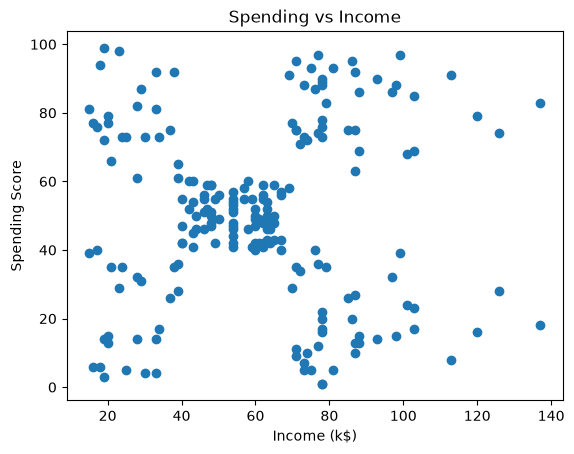

In [63]:
#Task0.2

plt.scatter(df["Income"], df["Spending"])
plt.xlabel("Income (k$)")
plt.ylabel("Spending Score")
plt.title("Spending vs Income")
plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye? Describe them in one line each (e.g. 'high income, low spending').

(b) Why can we not use accuracy or a train/test split to judge a clustering result?

**Your answers:**

(a) I can see 5 groups: low income + low spending (bottom left), low income + high spending (top left), middle income + middle spending (centre, the biggest group), high income + low spending (bottom right) and high income + high spending (top right).

(b) There are no correct labels to compare with, so accuracy means nothing, and we are not predicting anything so there is no test set. We judge clusters with silhouette, inertia and plots instead.

---

## Part 1 — K-Means From Scratch (30 minutes)

In the lecture you did K-Means by hand. Here you turn those steps into code and check your own function against scikit-learn. Using `KMeans()` inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: \|x - m\|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |

### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: `np.abs(x[:, None] - m[None, :])` has shape (9, 2).
- Cluster of each point: `dist.argmin(axis=1)`.

In [64]:
#Task1.1

x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
m = np.array([4, 11], dtype=float)

for i in range(1, 20):
    dist = np.abs(x[:, None] - m[None, :])
    labels = dist.argmin(axis=1)
    new_m = np.array([x[labels == 0].mean(), x[labels == 1].mean()])
    print("Iteration", i)
    print("C1:", x[labels == 0], "C2:", x[labels == 1])
    print("New centroids:", new_m)
    if np.allclose(new_m, m):
        break
    m = new_m

inertia = ((x - m[labels]) ** 2).sum()
print("Final centroids:", m)
print("Inertia:", inertia)

Iteration 1
C1: [2. 4. 3.] C2: [10. 12. 20. 30. 11. 25.]
New centroids: [ 3. 18.]
Iteration 2
C1: [ 2.  4. 10.  3.] C2: [12. 20. 30. 11. 25.]
New centroids: [ 4.75 19.6 ]
Iteration 3
C1: [ 2.  4. 10. 12.  3. 11.] C2: [20. 30. 25.]
New centroids: [ 7. 25.]
Iteration 4
C1: [ 2.  4. 10. 12.  3. 11.] C2: [20. 30. 25.]
New centroids: [ 7. 25.]
Final centroids: [ 7. 25.]
Inertia: 150.0


### Task 1.2 — Your own K-Means function vs scikit-learn

Turn your loop into a function, then show it gives the same answer as scikit-learn.

1. Write `my_kmeans(X, init_centroids, max_iter=100)` that works for any number of features and returns labels, centroids, inertia and the number of iterations. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
2. Use X2 = Income and Spending (200 x 2) with the first 5 rows as starting centroids. Run `my_kmeans` and `KMeans(n_clusters=5, init=<the same 5 rows>, n_init=1, tol=0, algorithm='lloyd')`, then compare the inertia and the centroids.

In [65]:
#Task1.2

def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    c = np.asarray(init_centroids, dtype=float).reshape(len(init_centroids), -1)

    for i in range(1, max_iter + 1):
        dist = np.sqrt(((X[:, None, :] - c[None, :, :]) ** 2).sum(axis=2))
        labels = dist.argmin(axis=1)
        new_c = np.array([X[labels == k].mean(axis=0) for k in range(len(c))])
        if np.allclose(new_c, c):
            break
        c = new_c

    inertia = ((X - c[labels]) ** 2).sum()
    return labels, c, inertia, i

labels1, c1, inertia1, iters1 = my_kmeans(x, [4, 11])
print("Centroids:", c1.ravel())
print("Inertia:", inertia1)
print("Iterations:", iters1)

Centroids: [ 7. 25.]
Inertia: 150.0
Iterations: 4


In [66]:
X2 = df[["Income", "Spending"]].values
start = X2[:5]

labels_my, c_my, inertia_my, iters_my = my_kmeans(X2, start)

sk = KMeans(n_clusters=5, init=start, n_init=1, tol=0, algorithm="lloyd")
sk.fit(X2)

print("My inertia:", inertia_my, "| iterations:", iters_my)
print("sklearn inertia:", sk.inertia_, "| iterations:", sk.n_iter_)
print("\nMy centroids:\n", c_my.round(2))
print("\nsklearn centroids:\n", sk.cluster_centers_.round(2))
print("\nSame centroids:", np.allclose(c_my, sk.cluster_centers_))

My inertia: 44448.45544793371 | iterations: 4
sklearn inertia: 44448.45544793371 | iterations: 4

My centroids:
 [[26.3  20.91]
 [25.73 79.36]
 [88.2  17.11]
 [86.54 82.13]
 [55.3  49.52]]

sklearn centroids:
 [[26.3  20.91]
 [25.73 79.36]
 [88.2  17.11]
 [86.54 82.13]
 [55.3  49.52]]

Same centroids: True


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn? If anything differed, explain why.

**Your answers:**

(a) After iteration 1 the centroids became 3 and 18. The point 10 is 7 away from 3 but 8 away from 18, so it is now closer to C1 and moves there (at the start it was closer to 11).

(b) The loop stops when the centroids stop moving (iteration 4 gave 7 and 25 again). It always stops because every step can only lower the inertia and there are only a limited number of ways to group the points. But it can get stuck in a local minimum, so the answer depends on the starting centroids.

(c) Yes. Both gave inertia 44448.46, the same 5 centroids and 4 iterations (my function also gave 7 and 25 with inertia 150 on Example 1). The only difference is tiny floating-point rounding.

---

## Part 2 — Choosing K: Elbow and Silhouette (25 minutes)

Nobody tells us K. Use the two lecture tools, the elbow and the silhouette, then calculate one silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |

### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit `KMeans(n_clusters=K, n_init=10, random_state=SEED)` and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.

,K,Inertia,Silhouette
0,2,181363.595960,0.296897
1,3,106348.373062,0.467614
2,4,73679.789039,0.493196
3,5,44448.455448,0.553932
4,6,37233.814511,0.539761
5,7,30241.343618,0.528810
6,8,25036.417604,0.454812
7,9,21916.794790,0.456109
8,10,20072.070939,0.441057


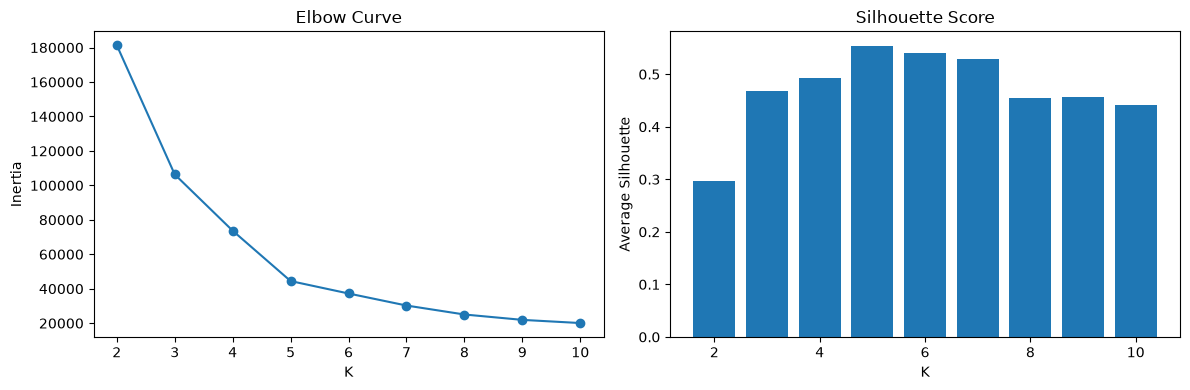

Best K by silhouette: 5


In [67]:
#Task2.1

results = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2)
    results.append([k, model.inertia_, silhouette_score(X2, model.labels_)])

k_table = pd.DataFrame(results, columns=["K", "Inertia", "Silhouette"])
display(k_table)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(k_table["K"], k_table["Inertia"], marker="o")
ax[0].set_xlabel("K")
ax[0].set_ylabel("Inertia")
ax[0].set_title("Elbow Curve")

ax[1].bar(k_table["K"], k_table["Silhouette"])
ax[1].set_xlabel("K")
ax[1].set_ylabel("Average Silhouette")
ax[1].set_title("Silhouette Score")

plt.tight_layout()
plt.show()

print("Best K by silhouette:", k_table.loc[k_table["Silhouette"].idxmax(), "K"])

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point, using only NumPy distances. Apply it to customer 1 (row 0) and compare with `silhouette_samples`.

In [68]:
#Task2.2

model5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
labels5 = model5.labels_

def silhouette_one(X, labels, i):
    dist = np.sqrt(((X - X[i]) ** 2).sum(axis=1))
    same = labels == labels[i]
    same[i] = False
    a = dist[same].mean()
    b = min(dist[labels == k].mean() for k in np.unique(labels) if k != labels[i])
    s = (b - a) / max(a, b)
    return a, b, s

a, b, s = silhouette_one(X2, labels5, 0)

print("a:", round(a, 4))
print("b:", round(b, 4))
print("s (by hand):", round(s, 4))
print("s (sklearn):", round(silhouette_samples(X2, labels5)[0], 4))

a: 24.6404
b: 42.2653
s (by hand): 0.417
s (sklearn): 0.417


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote your numbers.

(b) What is the silhouette of customer 1, and what does it tell you about where that customer sits?

(c) Why should we never choose K only by the lowest inertia?

**Your answers:**

(a) The elbow bends at K = 5: inertia drops a lot until K = 5 (73,680 at K = 4 to 44,448 at K = 5) and then only slowly (37,234 at K = 6). The silhouette is also highest at K = 5 (0.554). So both agree on K = 5.

(b) Customer 1 has silhouette 0.417 (a = 24.64, b = 42.27), so it sits in the right cluster but not deep inside it. My hand calculation matches sklearn exactly.

(c) Inertia always goes down when K goes up (with K = 200 it would be 0), so choosing the lowest inertia would just pick the biggest K, which is useless.

---

## Part 3 — Starting Points and Stability (15 minutes)

The lecture said 'starting points matter — run several starts and keep the best'. Here you measure how much.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |

### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in two settings: `init='random'` with `n_init=1`, and `init='k-means++'` with `n_init=10`.
2. For each setting print the lowest and the highest final inertia and the number of distinct values (round to 1 decimal).

In [69]:
#Task3.1

random_inertias = []
plus_inertias = []

for seed in range(30):
    r = KMeans(n_clusters=5, init="random", n_init=1, random_state=seed).fit(X2)
    p = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=seed).fit(X2)
    random_inertias.append(round(r.inertia_, 1))
    plus_inertias.append(round(p.inertia_, 1))

print("init='random', n_init=1")
print("Lowest:", min(random_inertias))
print("Highest:", max(random_inertias))
print("Distinct values:", len(set(random_inertias)))
print("Runs that found the lowest:", random_inertias.count(min(random_inertias)), "of 30")

print("\ninit='k-means++', n_init=10")
print("Lowest:", min(plus_inertias))
print("Highest:", max(plus_inertias))
print("Distinct values:", len(set(plus_inertias)))
print("Runs that found the lowest:", plus_inertias.count(min(plus_inertias)), "of 30")

init='random', n_init=1
Lowest: 44448.5
Highest: 91762.0
Distinct values: 14
Runs that found the lowest: 10 of 30

init='k-means++', n_init=10
Lowest: 44448.5
Highest: 44448.5
Distinct values: 1
Runs that found the lowest: 30 of 30


**Questions** (answer with your own numbers)

(a) How many different final inertia values did each setting produce?

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init solve this problem? Use your numbers.

**Your answers:**

(a) init='random' with n_init=1 gave 14 different inertia values (from 44,448.5 to 91,762.0). k-means++ with n_init=10 gave only 1 value (44,448.5).

(b) The starting centroids are picked randomly and the loop stops at the nearest local minimum, so different starts can end in different answers.

(c) k-means++ picks starting centroids far from each other, and n_init=10 tries 10 starts and keeps the lowest inertia. With random starts only 10 of 30 runs found 44,448.5, but k-means++ with 10 starts found it in all 30.

---

## Part 4 — Scaling: Units Decide the Clusters (20 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it by changing only the unit of Income.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |

### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, `n_init=10`, `random_state=SEED`).
2. Print the ARI between raw k$ and raw dollars, and between scaled k$ and scaled dollars.
3. Draw Age vs Income (in k$) twice: coloured by the raw-dollar clusters and by the scaled clusters.

In [70]:
#Task4.1

X_age_income = df[["Age", "Income"]].values.astype(float)
X_age_dollar = X_age_income.copy()
X_age_dollar[:, 1] = X_age_dollar[:, 1] * 1000

def cluster4(X):
    return KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X).labels_

raw_k = cluster4(X_age_income)
raw_dollar = cluster4(X_age_dollar)
scaled_k = cluster4(StandardScaler().fit_transform(X_age_income))
scaled_dollar = cluster4(StandardScaler().fit_transform(X_age_dollar))

print("ARI raw k$ vs raw dollars:", round(adjusted_rand_score(raw_k, raw_dollar), 4))
print("ARI scaled k$ vs scaled dollars:", round(adjusted_rand_score(scaled_k, scaled_dollar), 4))

ARI raw k$ vs raw dollars: 0.4897
ARI scaled k$ vs scaled dollars: 1.0


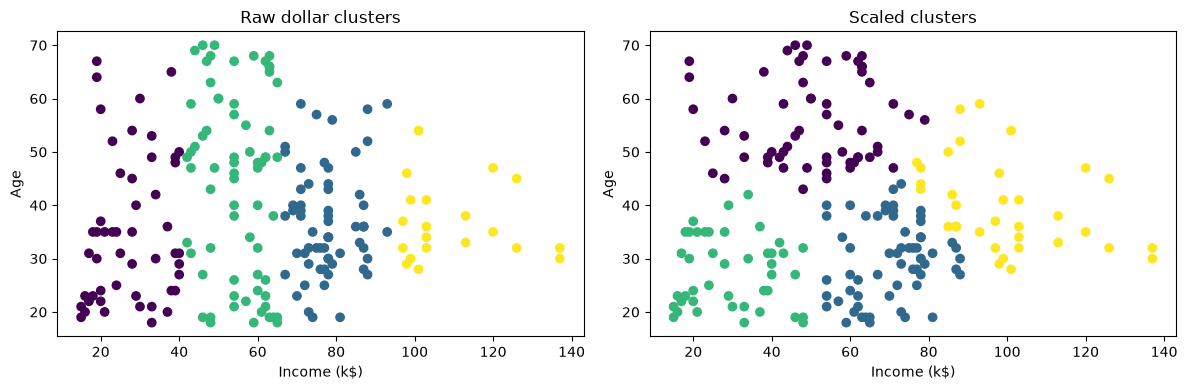

In [71]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].scatter(df["Income"], df["Age"], c=raw_dollar, cmap="viridis")
ax[0].set_xlabel("Income (k$)")
ax[0].set_ylabel("Age")
ax[0].set_title("Raw dollar clusters")

ax[1].scatter(df["Income"], df["Age"], c=scaled_k, cmap="viridis")
ax[1].set_xlabel("Income (k$)")
ax[1].set_ylabel("Age")
ax[1].set_title("Scaled clusters")

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula: which feature controls the distance now? What did scaling fix?

(b) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.

**Your answers:**

(a) The ARI between raw k$ and raw dollars is only 0.49, so the clusters changed just because of the unit. In dollars, Income differences are in thousands while Age differences are in tens, so Income controls the distance and Age is almost ignored (the left plot shows clusters that are just income bands). After scaling the ARI is 1.0, so the clusters are the same in both units. Scaling fixed the unit problem.

(b) I will scale whenever the features have different units or ranges (like age and income), and skip it only when all features are already on the same scale.

---

## Part 5 — Outliers (15 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and catch it with a simple distance rule.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |

### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (`n_init=10`, `random_state=SEED`) without and with the extra customer.
2. Print the cluster sizes and the centroids (sorted by income) for both fits.
3. Draw the two clusterings side by side.

Without extra customer
Sizes: [22 23 81 39 35]
Centroids (sorted by income):
[[25.7 79.4]
 [26.3 20.9]
 [55.3 49.5]
 [86.5 82.1]
 [88.2 17.1]]

With extra customer
Sizes: [ 23 100  39  38   1]
Centroids (sorted by income):
[[ 26.3  20.9]
 [ 48.3  56.5]
 [ 86.5  82.1]
 [ 87.   18.6]
 [400.   99. ]]



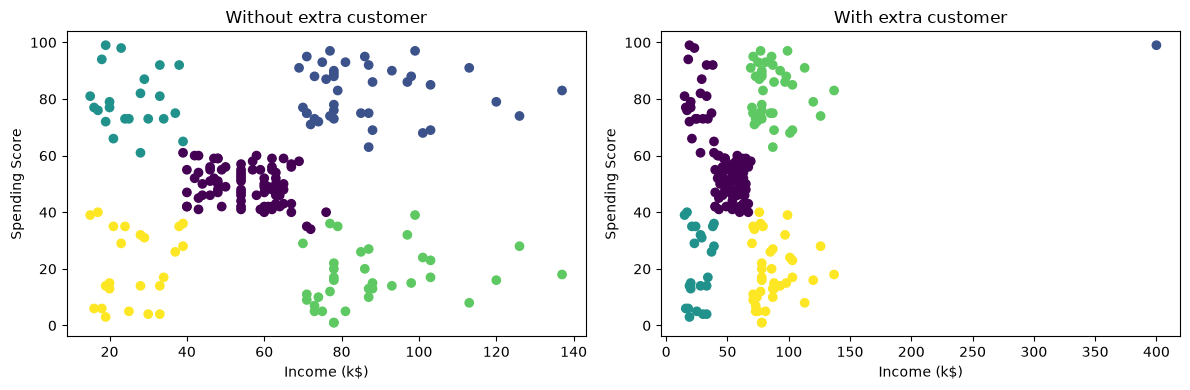

In [72]:
#Task5.1

extra = np.array([[400, 99]])
X2_extra = np.vstack([X2, extra])

model_normal = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
model_extra = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2_extra)

for name, model in [("Without extra customer", model_normal), ("With extra customer", model_extra)]:
    order = np.argsort(model.cluster_centers_[:, 0])
    print(name)
    print("Sizes:", np.bincount(model.labels_)[order])
    print("Centroids (sorted by income):")
    print(model.cluster_centers_[order].round(1))
    print()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].scatter(X2[:, 0], X2[:, 1], c=model_normal.labels_, cmap="viridis")
ax[0].set_xlabel("Income (k$)")
ax[0].set_ylabel("Spending Score")
ax[0].set_title("Without extra customer")

ax[1].scatter(X2_extra[:, 0], X2_extra[:, 1], c=model_extra.labels_, cmap="viridis")
ax[1].set_xlabel("Income (k$)")
ax[1].set_ylabel("Spending Score")
ax[1].set_title("With extra customer")

plt.tight_layout()
plt.show()

### Task 5.2 — Catch it with a distance rule

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). Is the extra customer flagged? Are any real customers flagged?

In [73]:
#Task5.2

dist_real = model_normal.transform(X2).min(axis=1)
dist_extra = model_normal.transform(extra).min(axis=1)[0]

threshold = dist_real.mean() + 3 * dist_real.std()

print("Mean distance:", round(dist_real.mean(), 2))
print("Std distance:", round(dist_real.std(), 2))
print("Threshold (mean + 3 std):", round(threshold, 2))
print("Extra customer distance:", round(dist_extra, 2))
print("Extra customer flagged:", dist_extra > threshold)
print("Real customers flagged:", (dist_real > threshold).sum())

df[dist_real > threshold][["CustomerID", "Age", "Income", "Spending"]]

Mean distance: 13.02
Std distance: 7.26
Threshold (mean + 3 std): 34.8
Extra customer distance: 313.92
Extra customer flagged: True
Real customers flagged: 4


,CustomerID,Age,Income,Spending
196,197,45,126,28
197,198,32,126,74
198,199,32,137,18
199,200,30,137,83


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Use the sizes and centroids.

(b) Did the rule catch the extra customer? If real customers were flagged too, are they errors or simply unusual customers?

(c) Name two ways to deal with outliers and one risk of simply deleting them.

**Your answers:**

(a) Without it the cluster sizes were 22, 23, 81, 39, 35. With it, the extra customer got its own cluster (size 1, centroid 400, 99) and the low income + high spending cluster (22 customers) disappeared into a big middle cluster of 100 customers. So one point wasted a cluster and merged real groups.

(b) Yes, its distance is 313.9, far above the threshold of 34.8. The rule also flagged 4 real customers (IDs 197 to 200, income 126 to 137). They are not errors, just the highest-income customers, so unusual but real.

(c) Two ways: remove the point if it is a data error, or cap (clip) its extreme value. The risk of simply deleting is losing real, valuable customers (like these big earners) and a real segment with them.

---

## Part 6 — Name the Segments and Wrap-Up (20 minutes)

Turn your clusters into segments that a marketing team could use.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Segment profile | The average Age, Income and Spending of each cluster. It tells you who is in the group. | `df.groupby('Cluster')[['Age','Income','Spending']].mean()` |
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |

### Task 6.1 — Profile and name the segments

Use the K you chose in Part 2 and the Income and Spending features.

1. Fit the final model (`n_init=10`, `random_state=SEED`) and add a Cluster column to the DataFrame.
2. Show the size and the mean Age, Income and Spending of each cluster.
3. Give each cluster a short name (e.g. 'High income, low spending') and one marketing action. Store the name in a Segment column.

In [74]:
#Task6.1

final_model = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
df["Cluster"] = final_model.labels_

profile = df.groupby("Cluster").agg(
    Size=("Age", "size"),
    Age=("Age", "mean"),
    Income=("Income", "mean"),
    Spending=("Spending", "mean")
).round(1)

display(profile)

segment_names = {
    0: "Average income, average spending",
    1: "High income, high spending",
    2: "Low income, high spending",
    3: "High income, low spending",
    4: "Low income, low spending"
}

df["Segment"] = df["Cluster"].map(segment_names)

,Size,Age,Income,Spending
Cluster,,,,
0,81,42.7,55.3,49.5
1,39,32.7,86.5,82.1
2,22,25.3,25.7,79.4
3,35,41.1,88.2,17.1
4,23,45.2,26.3,20.9


**Segment names and actions** (one line per cluster)

| Cluster | Segment name | Marketing action |
|---|---|---|
| 0 | Average income, average spending (81 customers) | Loyalty points and seasonal offers to keep them shopping |
| 1 | High income, high spending (39 customers) | VIP membership and early access to new products |
| 2 | Low income, high spending (22 customers) | Discounts and sale alerts since they love to spend |
| 3 | High income, low spending (35 customers) | Premium promotions to give them a reason to spend more |
| 4 | Low income, low spending (23 customers) | Cheap coupons and low-cost ads, do not spend much on them |

### Task 6.2 — Save and summarise

Produce a file someone else can use without running your notebook.

1. Save `customer_segments.csv` with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.
2. Write a 4–6 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, how you handled scaling and outliers, and one limitation.

In [75]:
#Task6.2

segments = df[["CustomerID", "Age", "Gender", "Income", "Spending", "Cluster", "Segment"]]
segments.to_csv("customer_segments.csv", index=False)

print("Saved customer_segments.csv:", segments.shape)
segments.head()

Saved customer_segments.csv: (200, 7)


,CustomerID,Age,Gender,Income,Spending,Cluster,Segment
0,1,19,Male,15,39,4,"Low income, low spending"
1,2,21,Male,15,81,2,"Low income, high spending"
2,3,20,Female,16,6,4,"Low income, low spending"
3,4,23,Female,16,77,2,"Low income, high spending"
4,5,31,Female,17,40,4,"Low income, low spending"


**Executive Summary** (4–6 lines)

I chose K = 5 because the elbow bends at K = 5 and the silhouette is highest there (0.554). The segments are: average income and spending (81 customers), high income and high spending (39), low income and high spending (22), high income and low spending (35), and low income and low spending (23). Income and Spending have similar ranges so I did not scale them, but Part 4 showed scaling is needed when units differ (ARI 0.49 without it, 1.0 with it). One extreme customer broke the clusters, and the mean + 3 std rule caught it, so outliers should be checked before clustering. One limitation is that there are only 200 customers and I used only 2 features (Age and Gender were left out), so the segments may change with more data.